# **Prediksi Harga Emas Antam Menggunakan Model Hybrid LSTM dan Residual Linear Tree Regression**

##Install Libraries

In [ ]:
!pip install linear-tree

In [ ]:
!pip install yfinance

In [ ]:
!pip install tensorflow

In [ ]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 2.6 MB/s eta 0:00:00


##Import Libraries

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import keras_tuner as kt
from tensorflow.keras.callbacks import EarlyStopping
from lineartree import LinearTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV

##Scrapping Data Kurs USD/IDR dari Yahoo Finance

In [ ]:
kurs = yf.download(
    "IDR=X",
    start="2010-01-01",
    end="2026-07-11",
    interval="1d"
)

df_kurs = kurs.reset_index()

df_kurs = df_kurs[['Date','Close']]

df_kurs.columns = ['Tanggal','USD_IDR']

df_kurs

/tmp/ipykernel_2046/2135688091.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  kurs = yf.download(
[*********************100%***********************]  1 of 1 completed


,Tanggal,USD_IDR
0,2010-01-01,9385.599609
1,2010-01-04,9364.200195
2,2010-01-05,9305.200195
3,2010-01-06,9218.099609
4,2010-01-07,9272.500000
...,...,...
4295,2026-07-06,17998.000000
4296,2026-07-07,18046.000000
4297,2026-07-08,17979.000000
4298,2026-07-09,18125.000000


In [ ]:
df_kurs[df_kurs['USD_IDR'] < 5000]

,Tanggal,USD_IDR
216,2010-11-01,888.109985
546,2012-02-07,892.000000


In [ ]:
df_kurs.loc[df_kurs['USD_IDR'] < 1000, 'USD_IDR'] *= 10

##Scrapping Data Harga Emas Dunia USD dari Yahoo Finance

In [ ]:
gold = yf.download(
    "GC=F",
    start="2010-01-01",
    end="2026-07-11",
    interval="1d"
)

df_gold = gold.reset_index()
df_gold = df_gold[['Date','Close']]
df_gold.columns = ['Tanggal','Gold_USD']

df_gold

/tmp/ipykernel_2046/4116330093.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  gold = yf.download(
[*********************100%***********************]  1 of 1 completed


,Tanggal,Gold_USD
0,2010-01-04,1117.699951
1,2010-01-05,1118.099976
2,2010-01-06,1135.900024
3,2010-01-07,1133.099976
4,2010-01-08,1138.199951
...,...,...
4148,2026-07-06,4155.100098
4149,2026-07-07,4145.299805
4150,2026-07-08,4070.899902
4151,2026-07-09,4130.600098


##Read Data Harga Emas Antam Logammulia

In [ ]:
df_antam = pd.read_csv('antam_price.csv')

##Data Understanding

In [ ]:
df_antam['Tanggal'].dtype

dtype('O')

In [ ]:
df_antam['Tanggal'] = pd.to_datetime(df_antam['Tanggal'], errors='coerce')
df_antam = df_antam.dropna(subset=['Tanggal'])

In [ ]:
df_gold['Tanggal'].dtype

dtype('<M8[ns]')

In [ ]:
df_kurs['Tanggal'].dtype

dtype('<M8[ns]')

In [ ]:
df_antam

,Tanggal,Harga
0,2010-01-04,408000
1,2010-01-05,410000
2,2010-01-06,410000
3,2010-01-07,412000
4,2010-01-08,410000
...,...,...
5056,2026-07-06,2670000
5057,2026-07-07,2655000
5058,2026-07-08,2641000
5059,2026-07-09,2633000


In [ ]:
df_antam.rename(columns={'Harga': 'Antam_IDR'}, inplace=True)

In [ ]:
df_antam

,Tanggal,Antam_IDR
0,2010-01-04,408000
1,2010-01-05,410000
2,2010-01-06,410000
3,2010-01-07,412000
4,2010-01-08,410000
...,...,...
5056,2026-07-06,2670000
5057,2026-07-07,2655000
5058,2026-07-08,2641000
5059,2026-07-09,2633000


In [ ]:
df = pd.merge(df_kurs, df_gold, on='Tanggal', how='inner')

In [ ]:
df

,Tanggal,USD_IDR,Gold_USD
0,2010-01-04,9364.200195,1117.699951
1,2010-01-05,9305.200195,1118.099976
2,2010-01-06,9218.099609,1135.900024
3,2010-01-07,9272.500000,1133.099976
4,2010-01-08,9212.700195,1138.199951
...,...,...,...
4141,2026-07-06,17998.000000,4155.100098
4142,2026-07-07,18046.000000,4145.299805
4143,2026-07-08,17979.000000,4070.899902
4144,2026-07-09,18125.000000,4130.600098


In [ ]:
df = pd.merge(df, df_antam, on='Tanggal', how='inner')

In [ ]:
df

,Tanggal,USD_IDR,Gold_USD,Antam_IDR
0,2010-01-04,9364.200195,1117.699951,408000
1,2010-01-05,9305.200195,1118.099976,410000
2,2010-01-06,9218.099609,1135.900024,410000
3,2010-01-07,9272.500000,1133.099976,412000
4,2010-01-08,9212.700195,1138.199951,410000
...,...,...,...,...
4082,2026-07-06,17998.000000,4155.100098,2670000
4083,2026-07-07,18046.000000,4145.299805,2655000
4084,2026-07-08,17979.000000,4070.899902,2641000
4085,2026-07-09,18125.000000,4130.600098,2633000


##Data Preparation

In [ ]:
df[df['Tanggal'].duplicated(keep=False)]

,Tanggal,USD_IDR,Gold_USD,Antam_IDR
60,2010-04-06,9037.299805,1135.099976,399000
61,2010-04-06,9037.299805,1135.099976,399000
84,2010-05-07,9220.299805,1210.000000,420000
85,2010-05-07,9220.299805,1210.000000,422000
86,2010-05-07,9220.299805,1210.000000,422000
...,...,...,...,...
3659,2024-10-24,15663.000000,2734.899902,1529000
3662,2024-10-29,15747.000000,2768.399902,1535000
3663,2024-10-29,15747.000000,2768.399902,1548000
3664,2024-10-29,15747.000000,2768.399902,1535000


In [ ]:
df = df.drop_duplicates(subset='Tanggal', keep='last')

In [ ]:
df

,Tanggal,USD_IDR,Gold_USD,Antam_IDR
0,2010-01-04,9364.200195,1117.699951,408000
1,2010-01-05,9305.200195,1118.099976,410000
2,2010-01-06,9218.099609,1135.900024,410000
3,2010-01-07,9272.500000,1133.099976,412000
4,2010-01-08,9212.700195,1138.199951,410000
...,...,...,...,...
4082,2026-07-06,17998.000000,4155.100098,2670000
4083,2026-07-07,18046.000000,4145.299805,2655000
4084,2026-07-08,17979.000000,4070.899902,2641000
4085,2026-07-09,18125.000000,4130.600098,2633000


In [ ]:
df.isnull().sum()

,0
Tanggal,0
USD_IDR,0
Gold_USD,0
Antam_IDR,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3980 entries, 0 to 4086
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Tanggal    3980 non-null   datetime64[ns]
 1   USD_IDR    3980 non-null   float64       
 2   Gold_USD   3980 non-null   float64       
 3   Antam_IDR  3980 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(1)
memory usage: 155.5 KB


In [ ]:
df.describe()

,Tanggal,USD_IDR,Gold_USD,Antam_IDR
count,3980,3980.000000,3980.000000,3.980000e+03
mean,2018-05-01 20:43:53.969849088,13222.082149,1769.471229,8.874296e+05
min,2010-01-04 00:00:00,8292.700195,1050.800049,3.940000e+05
25%,2014-03-09 06:00:00,11608.750000,1273.149963,5.680000e+05
50%,2018-05-12 12:00:00,13885.969727,1561.250000,6.590000e+05
75%,2022-07-06 06:00:00,14918.199951,1869.400024,9.920000e+05
max,2026-07-10 00:00:00,18190.300781,5318.399902,3.168000e+06
std,NaN,2496.258555,790.010492,5.316009e+05


In [ ]:
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

df

/tmp/ipykernel_2046/150967693.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Tanggal'] = pd.to_datetime(df['Tanggal'])


,USD_IDR,Gold_USD,Antam_IDR
Tanggal,,,
2010-01-04,9364.200195,1117.699951,408000
2010-01-05,9305.200195,1118.099976,410000
2010-01-06,9218.099609,1135.900024,410000
2010-01-07,9272.500000,1133.099976,412000
2010-01-08,9212.700195,1138.199951,410000
...,...,...,...
2026-07-06,17998.000000,4155.100098,2670000
2026-07-07,18046.000000,4145.299805,2655000
2026-07-08,17979.000000,4070.899902,2641000


In [ ]:
df = df.asfreq('D')

df = df.interpolate(method='linear')

df = df.ffill().bfill()

In [ ]:
df

,USD_IDR,Gold_USD,Antam_IDR
Tanggal,,,
2010-01-04,9364.200195,1117.699951,408000.0
2010-01-05,9305.200195,1118.099976,410000.0
2010-01-06,9218.099609,1135.900024,410000.0
2010-01-07,9272.500000,1133.099976,412000.0
2010-01-08,9212.700195,1138.199951,410000.0
...,...,...,...
2026-07-06,17998.000000,4155.100098,2670000.0
2026-07-07,18046.000000,4145.299805,2655000.0
2026-07-08,17979.000000,4070.899902,2641000.0


####Fitur Baru: GOLD IDR

In [ ]:
df['Gold_IDR'] = (df['Gold_USD'] / 31.1035) * df['USD_IDR']

In [ ]:
df

,USD_IDR,Gold_USD,Antam_IDR,Gold_IDR
Tanggal,,,,
2010-01-04,9364.200195,1117.699951,408000.0,3.365012e+05
2010-01-05,9305.200195,1118.099976,410000.0,3.345008e+05
2010-01-06,9218.099609,1135.900024,410000.0,3.366451e+05
2010-01-07,9272.500000,1133.099976,412000.0,3.377970e+05
2010-01-08,9212.700195,1138.199951,410000.0,3.371291e+05
...,...,...,...,...
2026-07-06,17998.000000,4155.100098,2670000.0,2.404343e+06
2026-07-07,18046.000000,4145.299805,2655000.0,2.405070e+06
2026-07-08,17979.000000,4070.899902,2641000.0,2.353134e+06


In [ ]:
df['USD_IDR'] = df['USD_IDR'].round().astype(int)
df['Gold_USD'] = df['Gold_USD'].round(2)
df['Antam_IDR'] = df['Antam_IDR'].round().astype(int)
df['Gold_IDR'] = df['Gold_IDR'].round().astype(int)

In [ ]:
df

,USD_IDR,Gold_USD,Antam_IDR,Gold_IDR
Tanggal,,,,
2010-01-04,9364,1117.7,408000,336501
2010-01-05,9305,1118.1,410000,334501
2010-01-06,9218,1135.9,410000,336645
2010-01-07,9272,1133.1,412000,337797
2010-01-08,9213,1138.2,410000,337129
...,...,...,...,...
2026-07-06,17998,4155.1,2670000,2404343
2026-07-07,18046,4145.3,2655000,2405070
2026-07-08,17979,4070.9,2641000,2353134


##Feature Selection & Normalisasi

In [ ]:
df = df[['USD_IDR','Gold_IDR','Antam_IDR']]

In [ ]:
df

,USD_IDR,Gold_IDR,Antam_IDR
Tanggal,,,
2010-01-04,9364,336501,408000
2010-01-05,9305,334501,410000
2010-01-06,9218,336645,410000
2010-01-07,9272,337797,412000
2010-01-08,9213,337129,410000
...,...,...,...
2026-07-06,17998,2404343,2670000
2026-07-07,18046,2405070,2655000
2026-07-08,17979,2353134,2641000


In [ ]:
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df)

In [ ]:
scaled_data

array([[0.10821461, 0.00688584, 0.00504686],
       [0.10225321, 0.00609857, 0.00576784],
       [0.09346267, 0.00694253, 0.00576784],
       ...,
       [0.97868041, 0.80070146, 0.81002163],
       [0.99343235, 0.82191755, 0.80713771],
       [0.99343235, 0.81583905, 0.81326604]])

##Sequence & Sliding Window

In [ ]:
def create_sequences(data, time_step=30):

    X = []
    y = []

    for i in range(len(data) - time_step):
        X.append(data[i:(i + time_step)])
        y.append(data[i + time_step, -1])

    return np.array(X), np.array(y)

data = scaled_data

X, y = create_sequences(data, 30)

In [ ]:
print("Hasil Pembentukan Sequence Data")

print(f"Jumlah sequence (X) : {len(X)}")
print(f"Jumlah target (y)   : {len(y)}")
print(f"Shape X             : {X.shape}")
print(f"Shape y             : {y.shape}")

print("\nContoh sequence pertama:")
print(X[0])

print("\nTarget pertama:")
print(y[0])

Hasil Pembentukan Sequence Data
Jumlah sequence (X) : 6002
Jumlah target (y)   : 6002
Shape X             : (6002, 30, 3)
Shape y             : (6002,)

Contoh sequence pertama:
[[0.10821461 0.00688584 0.00504686]
 [0.10225321 0.00609857 0.00576784]
 [0.09346267 0.00694253 0.00576784]
 [0.09891886 0.00739599 0.00648882]
 [0.09295746 0.00713304 0.00576784]
 [0.09073457 0.00730742 0.00612833]
 [0.08861271 0.00747984 0.00648882]
 [0.08638982 0.00764989 0.00684932]
 [0.08871375 0.00545301 0.00576784]
 [0.08568253 0.00589192 0.00540735]
 [0.08719814 0.00682325 0.00576784]
 [0.09427099 0.00638042 0.00504686]
 [0.09437203 0.00667446 0.00522711]
 [0.09447307 0.00696851 0.00540735]
 [0.09457411 0.00726255 0.0055876 ]
 [0.09467515 0.00755659 0.00576784]
 [0.1012428  0.00527115 0.00576784]
 [0.08992624 0.00257948 0.00504686]
 [0.09568556 0.00179655 0.0036049 ]
 [0.09841366 0.00239841 0.0036049 ]
 [0.10104072 0.00300146 0.0036049 ]
 [0.10376882 0.00360608 0.0036049 ]
 [0.10983126 0.00475825 0.0036

##Split Train & Test Data

In [ ]:
train_size = int(len(X) * 0.9)

X_train = X[:train_size]
X_test  = X[train_size:]

y_train = y[:train_size]
y_test  = y[train_size:]

In [ ]:
print(X_train.shape)

(5401, 30, 3)


In [ ]:
print("Hasil Pembagian Data")

print(f"Jumlah data training : {len(X_train)}")
print(f"Jumlah data testing  : {len(X_test)}")

print(f"Shape X_train : {X_train.shape}")
print(f"Shape X_test  : {X_test.shape}")

print(f"Shape y_train : {y_train.shape}")
print(f"Shape y_test  : {y_test.shape}")

print(f"Rasio training : {len(X_train)/len(X)*100:.0f}%")
print(f"Rasio testing  : {len(X_test)/len(X)*100:.0f}%")

Hasil Pembagian Data
Jumlah data training : 5401
Jumlah data testing  : 601
Shape X_train : (5401, 30, 3)
Shape X_test  : (601, 30, 3)
Shape y_train : (5401,)
Shape y_test  : (601,)
Rasio training : 90%
Rasio testing  : 10%


##LSTM

In [ ]:
def build_model(hp):
    model = Sequential()

    model.add(LSTM(
        units=hp.Int('units', 32, 128, step=32),
        input_shape=(30, 3)
    ))

    model.add(Dropout(
        hp.Float('dropout', 0.1, 0.5, step=0.1)
    ))

    model.add(Dense(1))

    model.compile(
        optimizer=hp.Choice('optimizer', ['adam', 'rmsprop']),
        loss='mean_squared_error'
    )

    return model

In [ ]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_loss',
    max_trials=20,
    executions_per_trial=2,
    directory='tuning_lstm',
    project_name='lstm_m5_hybrid'
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [ ]:
tuner.search(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)

Trial 20 Complete [00h 01m 30s]
val_loss: 0.00025765393365873024

Best val_loss So Far: 0.0001260454737348482
Total elapsed time: 00h 36m 00s


In [ ]:
best_model = tuner.get_best_models(1)[0]

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 12 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


##Training

In [ ]:
history = best_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)

Epoch 1/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - loss: 2.0656e-05 - val_loss: 8.7169e-05
Epoch 2/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 1.9560e-05 - val_loss: 1.0257e-04
Epoch 3/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - loss: 1.7383e-05 - val_loss: 1.4753e-04
Epoch 4/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 1.5366e-05 - val_loss: 1.0451e-04
Epoch 5/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - loss: 1.6103e-05 - val_loss: 9.2372e-05
Epoch 6/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 1.6859e-05 - val_loss: 7.3413e-05
Epoch 7/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - loss: 1.5395e-05 - val_loss: 7.5776e-05
Epoch 8/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - loss: 1.5621e-05 - val_loss: 9.6664e-05
Epoch 9/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 1.5956e-05 - val_loss: 1.6790e-04
Epoch 10/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - loss: 1.7244e-05 - val_loss: 1.8781e-04
Epoch 11/50
169/169 ━━━━━━━━━━━━━━━━━━━━ 6s 33m

##Predict

In [ ]:
y_pred_lstm = best_model.predict(X_test).flatten()

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step


##Residual M5 Hybrid Linear Tree Regresion

In [ ]:
train_pred_lstm = best_model.predict(X_train).flatten()

residual_train = y_train.flatten() - train_pred_lstm
residual_test  = y_test.flatten()  - y_pred_lstm

169/169 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step


In [ ]:
print("Hasil Perhitungan Residual")

print(f"Shape residual_train : {residual_train.shape}")
print(f"Shape residual_test  : {residual_test.shape}")

print("\n5 Residual training pertama:")
print(residual_train[:5])

print("\n5 Residual testing pertama:")
print(residual_test[:5])

Hasil Perhitungan Residual
Shape residual_train : (5401,)
Shape residual_test  : (601,)

5 Residual training pertama:
[ 0.00050846 -0.00067979 -0.00088087 -0.00010698  0.0002582 ]

5 Residual testing pertama:
[0.00043523 0.00035876 0.00455465 0.00479159 0.00549404]


In [ ]:
def create_tabular(X_seq):
    return X_seq.reshape(X_seq.shape[0], -1)

X_train_tab = create_tabular(X_train)
X_test_tab  = create_tabular(X_test)

In [ ]:
print("Hasil Transformasi Data Tabular")

print(f"Shape X_train sebelum : {X_train.shape}")
print(f"Shape X_train sesudah : {X_train_tab.shape}")

print(f"\nShape X_test sebelum : {X_test.shape}")
print(f"Shape X_test sesudah : {X_test_tab.shape}")

Hasil Transformasi Data Tabular
Shape X_train sebelum : (5401, 30, 3)
Shape X_train sesudah : (5401, 90)

Shape X_test sebelum : (601, 30, 3)
Shape X_test sesudah : (601, 90)


In [ ]:
m5 = LinearTreeRegressor(base_estimator=LinearRegression())

param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [6, 10, 20],
    'min_samples_leaf': [3, 5, 10]
}

grid = GridSearchCV(
    m5,
    param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid.fit(X_train_tab, residual_train)

best_m5 = grid.best_estimator_

print("Best Params Linear Tree Regression:", grid.best_params_)

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Best Params Linear Tree Regression: {'max_depth': 3, 'min_samples_leaf': 3, 'min_samples_split': 6}


In [ ]:
residual_pred = best_m5.predict(X_test_tab)

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
final_pred = y_pred_lstm + residual_pred

##Inverse Scaling

In [ ]:
temp_pred = np.zeros((len(final_pred), df.shape[1]))
temp_pred[:, -1] = final_pred
final_inverse = scaler.inverse_transform(temp_pred)[:, -1]

In [ ]:
y_test_reshape = y_test.reshape(-1,1)
temp_actual = np.zeros((len(y_test_reshape), df.shape[1]))
temp_actual[:, -1] = y_test_reshape.flatten()
actual_inverse = scaler.inverse_transform(temp_actual)[:, -1]

In [ ]:
print("Hasil Inverse Scaling")

print("5 Prediksi pertama (Normalisasi)")
print(final_pred[:5])

print("\n5 Prediksi pertama (Harga Asli)")
print(final_inverse[:5])

print("\n5 Data Aktual (Harga Asli)")
print(actual_inverse[:5])

Hasil Inverse Scaling
5 Prediksi pertama (Normalisasi)
[0.39059665 0.39214465 0.39156818 0.3947718  0.40042469]

5 Prediksi pertama (Harga Asli)
[1477515.12022596 1481809.25067048 1480210.13293194 1489096.96261864
 1504778.07839494]

5 Data Aktual (Harga Asli)
[1474000. 1476000. 1491000. 1498000. 1508000.]


##Hasil Predict

In [ ]:
dates = df.index[30 + train_size:]

result = pd.DataFrame({
    'Tanggal': dates,
    'Actual': actual_inverse,
    'Prediction': final_inverse
})

result.set_index('Tanggal', inplace=True)

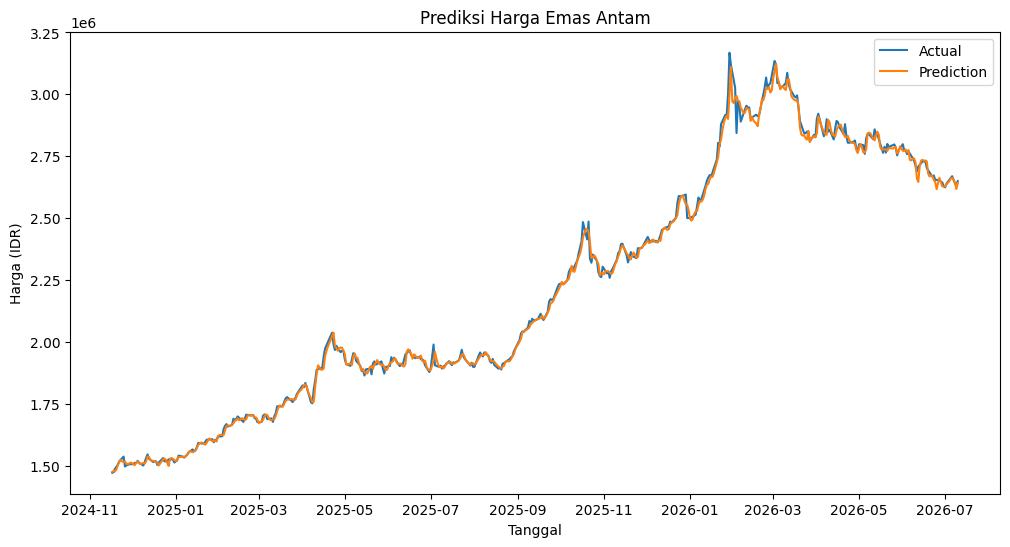

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(result.index, result['Actual'], label='Actual')
plt.plot(result.index, result['Prediction'], label='Prediction')

plt.title("Prediksi Harga Emas Antam")
plt.xlabel("Tanggal")
plt.ylabel("Harga (IDR)")
plt.legend()

plt.show()

##Evaluasi

In [ ]:
mae  = mean_absolute_error(actual_inverse, final_inverse)
rmse = np.sqrt(mean_squared_error(actual_inverse, final_inverse))
mape = np.mean(np.abs((actual_inverse - final_inverse) / actual_inverse)) * 100
r2   = r2_score(actual_inverse, final_inverse)

print("MAE  :", mae)
print("RMSE :", rmse)
print("MAPE :", mape)
print("R2   :", r2)

MAE  : 12501.31110775505
RMSE : 20464.56666388784
MAPE : 0.5392741178499881
R2   : 0.9982294187257144


##Forecast 90 hari

In [ ]:
last_sequence = scaled_data[-30:]

####Looping Prediksi

In [ ]:
future_days = 90
future_predictions = []
future_tab = []

current_sequence = last_sequence.copy()

for i in range(future_days):

    X_input = current_sequence.reshape(1, 30, 3)

    pred = best_model.predict(X_input, verbose=0)
    future_predictions.append(pred[0,0])

    future_tab.append(current_sequence.flatten())

    last_gold = current_sequence[-1, 0]
    last_usd  = current_sequence[-1, 1]

    new_row = np.array([last_gold, last_usd, pred[0,0]])
    current_sequence = np.vstack([current_sequence[1:], new_row])

future_tab = np.array(future_tab)

future_residual = best_m5.predict(future_tab)

future_final = np.array(future_predictions) + future_residual

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
future_dates = pd.date_range(
    start=df.index[-1] + pd.Timedelta(days=1),
    periods=future_days
)

In [ ]:
temp_future = np.zeros((future_days, df.shape[1]))
temp_future[:, -1] = future_final

future_inverse = scaler.inverse_transform(temp_future)[:, -1]

In [ ]:
forecast_df = pd.DataFrame({
    "Tanggal": future_dates,
    "Forecast_Antam": future_inverse
})

forecast_df.set_index("Tanggal", inplace=True)

forecast_df = forecast_df.round(0).astype(int)
forecast_df

,Forecast_Antam
Tanggal,
2026-07-11,2641747
2026-07-12,2635523
2026-07-13,2635930
2026-07-14,2637763
2026-07-15,2638565
...,...
2026-10-04,2615625
2026-10-05,2615625
2026-10-06,2615624


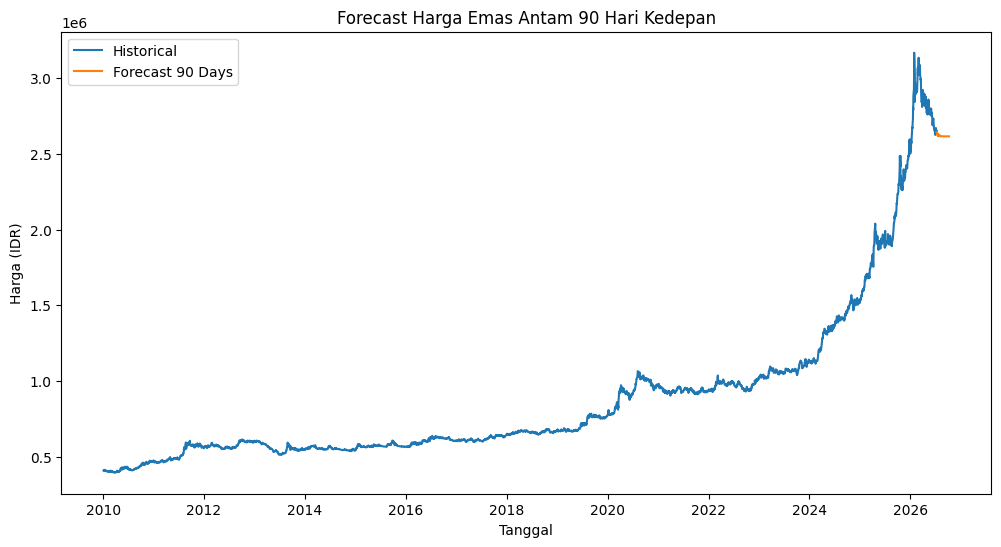

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(df.index, df['Antam_IDR'], label="Historical")
plt.plot(forecast_df.index, forecast_df['Forecast_Antam'], label="Forecast 90 Days")

plt.title("Forecast Harga Emas Antam 90 Hari Kedepan")
plt.xlabel("Tanggal")
plt.ylabel("Harga (IDR)")
plt.legend()

plt.show()

In [ ]:
forecast_df.to_csv('forecast.csv', index=False)

In [ ]:
df['USD_IDR'].to_csv('kurs.csv')

In [ ]:
df['Gold_IDR'].to_csv('gold_idr.csv')

In [ ]:
metrics = {
    "MAE": mae,
    "RMSE": rmse,
    "MAPE": mape,
    "R2": r2
}

import pandas as pd
pd.DataFrame([metrics]).to_csv("metrics.csv", index=False)

In [ ]:
df[df['USD_IDR'] < 5000]

,USD_IDR,Gold_IDR,Antam_IDR
Tanggal,,,


In [ ]:
df[df['Gold_IDR'] < 300000]

,USD_IDR,Gold_IDR,Antam_IDR
Tanggal,,,


In [ ]:
forecast_df

,Forecast_Antam
Tanggal,
2026-07-11,2641747
2026-07-12,2635523
2026-07-13,2635930
2026-07-14,2637763
2026-07-15,2638565
...,...
2026-10-04,2615625
2026-10-05,2615625
2026-10-06,2615624
